# Benchmark: zero-inflated counts

A zero-inflated Poisson (ZIP) count is 0 with probability \(\pi\) and Poisson(\( \mu \)) otherwise, so the expectation is \((1-\pi)\mu\) rather than \(\mu\). This study asks whether the `ZIPoLSS` family recovers that distribution as well as a zero-inflated Poisson maximum likelihood fit, and what a user gets from the count models they already know: `Poisson`, `NBinomial`, a hurdle model, and `autospec`. A hurdle model has two parts: a binary model for whether the count is positive (`Binomial` on \(y > 0\)), and a zero-truncated negative binomial for the positive counts (`Hurdle`, fitted to the positive counts only).

Two tasks, each with four standard normal predictors: \(x_1\) and \(x_2\) drive the Poisson mean, \(z\) drives the zero probability, and `noise` has no effect.

* **linear**: \(\log \mu = 0.15 + 0.55 x_1 - 0.30 x_2\), \(\operatorname{logit} \pi = -0.35 + 0.95 z\).
* **smooth**: \(\log \mu = 0.05 + \sin(1.5 x_1) + 0.30 x_2\), with the same inflation equation.

Each seed draws 1,500 training rows and an independent 4,000 test rows. The mboostrs step counts (`mstop`, the number of boosting steps) are chosen by 5-fold cross-validation on the training rows, with the step length `nu=0.1`; the grid is extended once from 1,600 to 3,200 steps if the chosen step is the cap. The linear ZIP fit is `glmboostLSS`; the smooth one is `gamboostLSS` with `bbs(x1, df=4)` (a P-spline, a penalized cubic B-spline) and linear terms for the other columns. statsmodels' `ZeroInflatedPoisson` is fit by BFGS (a quasi-Newton optimizer of the likelihood) on the same columns, with a B-spline of \(x_1\) (4 df, knots fixed on \([-6, 6]\)) on the smooth task. R gamboostLSS was not run; the maximum likelihood fit is the reference for the linear design. Results were measured with mboostrs 0.1.3.

The score is the mean negative log probability of the test counts, in nats per row (lower is better). Mean absolute error of \(E[Y \mid x]\) and the RMSE of \(P(Y=0)\) are reported beside it. The absolute error alone hides the zero inflation: a Poisson mean can sit close to \((1-\pi)\mu\) while putting too little mass at zero.

:::{admonition} What this study estimates
:class: dropdown

| | |
|---|---|
| **Target** | the conditional distribution of a zero-inflated Poisson count |
| **Observed response** | a simulated count |
| **Estimand** | test mean negative log probability; absolute error of \(E[Y \mid x]\); RMSE of \(P(Y=0)\) |
| **Units** | nats per row; counts; probability |
| **Sampling unit** | one row; 1,500 training and 4,000 test rows per seed |
| **Dependence** | independent rows |
| **Split / resampling unit** | a fresh test sample; 5-fold cross-validation on the training rows chooses `mstop` |
| **Tuning** | mboostrs: `cvrisk`, extended once if the optimum is the largest budget; statsmodels: BFGS maximum likelihood, no selection |
| **Uncertainty** | mean over 4 seeds |
| **Claim type** | methodological |
:::


In [1]:
# Read the recorded runs; this page does not refit the models.
import json
from pathlib import Path

import altair as alt
import polars as pl

from bench_tables import table

bench = json.loads(Path("bench_zero_inflated.json").read_text())


In [2]:
# Preserve the recorded method and replication for each score.
rows = []
for record in bench["results"]:
    rows.append({
        "task": record["task"],
        "method": record["method"],
        "nll": record["nll"],
        "mae": record["mae"],
        "p0_rmse": record["p0_rmse"],
        "seconds": record["seconds"],
        "mae_if_mu": record.get("mae_if_mu_used_as_mean"),
    })
raw = pl.DataFrame(rows)


In [3]:
# Average the recorded scores within each task and method.
summary = (
    raw.group_by("task", "method")
    .agg(
        pl.col("nll").mean(),
        pl.col("mae").mean(),
        pl.col("p0_rmse").mean(),
        pl.col("seconds").mean(),
        pl.col("mae_if_mu").mean(),
    )
    .sort("task", "nll")
)


In [4]:
# Retrieve recorded scores and convergence evidence for the interpretation.
def value(task, method, column):
    hit = summary.filter((pl.col("task") == task) & (pl.col("method") == method))
    return float(hit[column][0])


In [5]:
# Read the recorded runs; this page does not refit the models.
scored = summary.filter(pl.col("method") != "generating ZIP")
wide_bits = []


In [6]:
# Preserve the recorded method and replication for each score.
for task, prefix in (("linear", "lin"), ("smooth", "sm")):
    wide_bits.append(
        scored.filter(pl.col("task") == task).select(
            "method",
            pl.col("nll").alias(f"{prefix}_nll"),
            pl.col("mae").alias(f"{prefix}_mae"),
            pl.col("p0_rmse").alias(f"{prefix}_p0"),
            pl.col("seconds").alias(f"{prefix}_seconds"),
        )
    )
wide = wide_bits[0].join(wide_bits[1], on="method", how="full", coalesce=True).sort("lin_nll")


In [7]:
# Display the headline scores with their units and convergence notes.
table(
    wide,
    title="Zero-inflated Poisson counts",
    subtitle="Mean over 4 seeds; 1,500 training rows and 4,000 test rows",
    spanners={
        "Linear mean and inflation": ["lin_nll", "lin_mae", "lin_p0", "lin_seconds"],
        "Smooth mean, linear inflation": ["sm_nll", "sm_mae", "sm_p0", "sm_seconds"],
    },
    labels={
        "lin_nll": "log score ↓", "lin_mae": "MAE ↓", "lin_p0": "P(0) RMSE ↓", "lin_seconds": "seconds",
        "sm_nll": "log score ↓", "sm_mae": "MAE ↓", "sm_p0": "P(0) RMSE ↓", "sm_seconds": "seconds",
    },
    better={"lin_nll": "min", "lin_mae": "min", "lin_p0": "min",
            "sm_nll": "min", "sm_mae": "min", "sm_p0": "min"},
    formats={"lin_seconds": 2, "sm_seconds": 2},
)


GT(_tbl_data=shape: (5, 9)
┌───────────────┬──────────┬──────────┬──────────┬───┬──────────┬──────────┬──────────┬────────────┐
│ method        ┆ lin_nll  ┆ lin_mae  ┆ lin_p0   ┆ … ┆ sm_nll   ┆ sm_mae   ┆ sm_p0    ┆ sm_seconds │
│ ---           ┆ ---      ┆ ---      ┆ ---      ┆   ┆ ---      ┆ ---      ┆ ---      ┆ ---        │
│ str           ┆ f64      ┆ f64      ┆ f64      ┆   ┆ f64      ┆ f64      ┆ f64      ┆ f64        │
╞═══════════════╪══════════╪══════════╪══════════╪═══╪══════════╪══════════╪══════════╪════════════╡
│ mboostrs      ┆ 1.09974  ┆ 0.866824 ┆ 0.032378 ┆ … ┆ 1.06009  ┆ 0.84623  ┆ 0.034846 ┆ 0.871656   │
│ ZIPoLSS       ┆          ┆          ┆          ┆   ┆          ┆          ┆          ┆            │
│ statsmodels   ┆ 1.099815 ┆ 0.866755 ┆ 0.032671 ┆ … ┆ 1.520945 ┆ 0.955615 ┆ 0.053317 ┆ 0.092691   │
│ ZIP MLE       ┆          ┆          ┆          ┆   ┆          ┆          ┆          ┆            │
│ mboostrs      ┆ 1.104127 ┆ 0.881634 ┆ 0.05135  ┆ … ┆ 1.062563 ┆ 0.852749 ┆ 0.058973 ┆ 4.119184   │
│ hurdle        ┆          ┆          ┆          ┆   ┆          ┆          ┆          ┆            │
│ (Binomial +   ┆          ┆          ┆          ┆   ┆          ┆          ┆          ┆            │
│ Hu…           ┆          ┆          ┆          ┆   ┆          ┆          ┆          ┆            │
│ mboostrs      ┆ 1.145815 ┆ 0.876665 ┆ 0.083442 ┆ … ┆ 1.105582 ┆ 0.855505 ┆ 0.081331 ┆ 1.055246   │
│ NBinomial     ┆          ┆          ┆          ┆   ┆          ┆          ┆          ┆            │
│ mboostrs      ┆ 1.218643 ┆ 0.878203 ┆ 0.150029 ┆ … ┆ 1.184231 ┆ 0.856267 ┆ 0.14896  ┆ 0.153178   │
│ Poisson       ┆          ┆          ┆          ┆   ┆          ┆          ┆          ┆            │
└───────────────┴──────────┴──────────┴──────────┴───┴──────────┴──────────┴──────────┴────────────┘, _body=<great_tables._gt_data.Body object at 0x108e24f80>, _boxhead=Boxhead([ColInfo(var='method', type=<ColInfoTypeEnum.stub: 2>, column_label='method', column_align='left', column_width=None, stub_level=0), ColInfo(var='lin_nll', type=<ColInfoTypeEnum.default: 1>, column_label='log score ↓', column_align='right', column_width=None, stub_level=None), ColInfo(var='lin_mae', type=<ColInfoTypeEnum.default: 1>, column_label='MAE ↓', column_align='right', column_width=None, stub_level=None), ColInfo(var='lin_p0', type=<ColInfoTypeEnum.default: 1>, column_label='P(0) RMSE ↓', column_align='right', column_width=None, stub_level=None), ColInfo(var='lin_seconds', type=<ColInfoTypeEnum.default: 1>, column_label='seconds', column_align='right', column_width=None, stub_level=None), ColInfo(var='sm_nll', type=<ColInfoTypeEnum.default: 1>, column_label='log score ↓', column_align='right', column_width=None, stub_level=None), ColInfo(var='sm_mae', type=<ColInfoTypeEnum.default: 1>, column_label='MAE ↓', column_align='right', column_width=None, stub_level=None), ColInfo(var='sm_p0', type=<ColInfoTypeEnum.default: 1>, column_label='P(0) RMSE ↓', column_align='right', column_width=None, stub_level=None), ColInfo(var='sm_seconds', type=<ColInfoTypeEnum.default: 1>, column_label='seconds', column_align='right', column_width=None, stub_level=None)]), _stub=<great_tables._gt_data.Stub object at 0x10a723950>, _spanners=Spanners([SpannerInfo(spanner_id='Linear mean and inflation', spanner_level=0, spanner_label='Linear mean and inflation', spanner_units=None, spanner_pattern=None, vars=['lin_nll', 'lin_mae', 'lin_p0', 'lin_seconds'], built=None), SpannerInfo(spanner_id='Smooth mean, linear inflation', spanner_level=0, spanner_label='Smooth mean, linear inflation', spanner_units=None, spanner_pattern=None, vars=['sm_nll', 'sm_mae', 'sm_p0', 'sm_seconds'], built=None)]), _heading=Heading(title='Zero-inflated Poisson counts', subtitle='Mean over 4 seeds; 1,500 training rows and 4,000 test rows', preheader=None), _stubhead='Method', _summary_rows=<great_tables._gt_data.SummaryRows object at 0x10a159e80>, _summary_rows_grand=<great_tables._gt_da

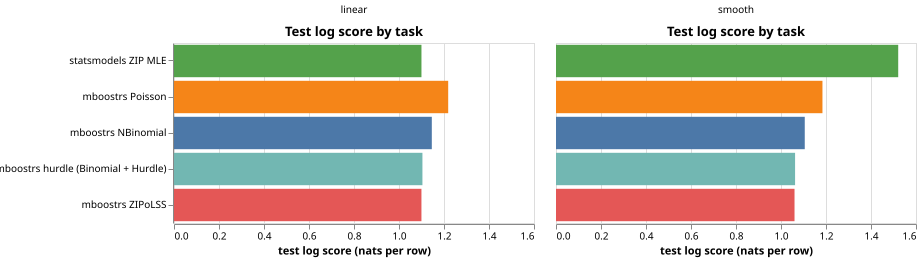

In [8]:
chart_rows = summary.filter(pl.col("method") != "generating ZIP")
alt.Chart(chart_rows).mark_bar().encode(
    x=alt.X("nll:Q", title="test log score (nats per row)", scale=alt.Scale(zero=False)),
    y=alt.Y("method:N", sort="-x", title=None),
    color=alt.Color("method:N", legend=None),
).properties(
    width=360, height=180,
    title="Test log score by task",
).facet(column=alt.Column("task:N", title=None))


## The linear task

`ZIPoLSS` matches the ZIP maximum likelihood fit. Mean test log score
{eval}`f"{value('linear', 'mboostrs ZIPoLSS', 'nll'):.4f}"` nats per row against
{eval}`f"{value('linear', 'statsmodels ZIP MLE', 'nll'):.4f}"` for statsmodels, and
{eval}`f"{value('linear', 'generating ZIP', 'nll'):.4f}"` for the generating
distribution. The RMSE of \(P(Y=0)\) is
{eval}`f"{value('linear', 'mboostrs ZIPoLSS', 'p0_rmse'):.3f}"` against
{eval}`f"{value('linear', 'statsmodels ZIP MLE', 'p0_rmse'):.3f}"`.

The fitted boosting paths require many updates. On all four seeds the
cross-validated risk was still falling at 3,200 updates per parameter, the
largest budget tried, and mboostrs issued its boundary warning (the warning
given when the selected step count equals the largest one tried). The test
log score had already reached the maximum likelihood fit, so the warning
concerns the training criterion; it does not indicate a remaining gap on
the test sample.

A plain `Poisson` fit, which has no term for the extra zeros, is the baseline. Its test log score
is {eval}`f"{value('linear', 'mboostrs Poisson', 'nll'):.4f}"`, about
{eval}`f"{value('linear', 'mboostrs Poisson', 'nll') - value('linear', 'mboostrs ZIPoLSS', 'nll'):.3f}"`
nats per row worse, and its \(P(Y=0)\) RMSE is
{eval}`f"{value('linear', 'mboostrs Poisson', 'p0_rmse'):.3f}"` against
{eval}`f"{value('linear', 'mboostrs ZIPoLSS', 'p0_rmse'):.3f}"`. Absolute error
of the mean barely moves:
{eval}`f"{value('linear', 'mboostrs Poisson', 'mae'):.3f}"` counts against
{eval}`f"{value('linear', 'mboostrs ZIPoLSS', 'mae'):.3f}"`. A comparison that
only reports MAE would call the Poisson fit adequate.

`NBinomial` absorbs some of the extra zeros into the dispersion and scores
{eval}`f"{value('linear', 'mboostrs NBinomial', 'nll'):.4f}"`. The hurdle
model (`Binomial` for `y > 0`, and `Hurdle` on the positive counts) scores
{eval}`f"{value('linear', 'mboostrs hurdle (Binomial + Hurdle)', 'nll'):.4f}"`,
close to the ZIP fits, in
{eval}`f"{value('linear', 'mboostrs hurdle (Binomial + Hurdle)', 'seconds'):.1f}"`
seconds per seed because each part is cross-validated and the truncated
negative binomial re-estimates its dispersion at every step. `ZIPoLSS` takes
{eval}`f"{value('linear', 'mboostrs ZIPoLSS', 'seconds'):.2f}"` seconds and the
BFGS fit {eval}`f"{value('linear', 'statsmodels ZIP MLE', 'seconds'):.2f}"`.
The speed gap is the difference between component-wise boosting to thousands
of steps and a four-column maximum likelihood fit; R gamboostLSS was not
timed.

`predict(type="response")` on a `ZIPoLSS` fit returns two parameters: `mu`,
the Poisson mean of the count component, and `sigma`, which in `ZIPoLSS` is
the extra-zero probability \(\pi\). Using `mu` as \(E[Y]\) raises the test
MAE from {eval}`f"{value('linear', 'mboostrs ZIPoLSS', 'mae'):.3f}"` to
{eval}`f"{value('linear', 'mboostrs ZIPoLSS', 'mae_if_mu'):.3f}"` counts.
`predict(type="mean")` and `mean()` return \((1-\pi)\mu\).

## The smooth mean

`ZIPoLSS` with a P-spline on \(x_1\) reaches
{eval}`f"{value('smooth', 'mboostrs ZIPoLSS', 'nll'):.4f}"` nats per row. The
generating distribution scores
{eval}`f"{value('smooth', 'generating ZIP', 'nll'):.4f}"`. The hurdle model scores
{eval}`f"{value('smooth', 'mboostrs hurdle (Binomial + Hurdle)', 'nll'):.4f}"`,
`NBinomial` {eval}`f"{value('smooth', 'mboostrs NBinomial', 'nll'):.4f}"` and
`Poisson` {eval}`f"{value('smooth', 'mboostrs Poisson', 'nll'):.4f}"`.

The B-spline ZIP maximum likelihood fit is not a usable reference on this task.
BFGS reports convergence on every seed, and the mean test log score is
{eval}`f"{value('smooth', 'statsmodels ZIP MLE', 'nll'):.3f}"`, pulled up by
seeds 2 and 3. On seed 3 the Poisson mean \(\mu\) of the statsmodels fit has
RMSE 1160 against the generating \(\mu\); on seed 2 it is 18.6. The \(\mu\)
of `ZIPoLSS` stays near the generating one (mean RMSE 0.36 across the four
seeds). A few test values of \(x_1\) fall outside the training range of
`bbs(x1)`; prediction warns, and the basis is extrapolated at its edge
slope. Those warnings are not shown with the scores.

## Prediction and parameter accessors

The examples below use the first linear training sample (1,500 rows, 58% zeros).

Passing a distributional family to a single-predictor fit, or a
single-predictor family to a distributional fit, raises an error that names
the fit to use. `gamboost(family=ZIPoLSS())` raises:

> {eval}`next(p["detail"] for p in bench["usability"]["probes"] if p["label"] == "gamboost(family=ZIPoLSS())")`

and `gamboostLSS(family=Poisson())` raises:

> {eval}`next(p["detail"] for p in bench["usability"]["probes"] if p["label"] == "gamboostLSS(family=Poisson())")`

`autospec` on the same frame returns family
{eval}`bench["usability"]["autospec_family"]` and the formula
{eval}`bench["usability"]["autospec_formula"]`, in
{eval}`f"{bench['usability']['autospec_seconds']:.1f}"` seconds. Its data
checks report that 58% of the response is zero and name
`scan_lss_families(..., support="counts")`, which ranks `ZIPoLSS` and
`ZeroAdjustedPoissonLSS`; its own family step does not try those two. That
step ranks the distributional family `ZINBLSS` first among the count
families it compares, and recommends `NBinomial`, the best single-parameter
family, with the advice to fit `ZINBLSS` with `glmboostLSS`. Neither is the
generating model. On this sample `scan_lss_families` with `glmboostLSS`,
`mstop=80` and 5-fold `cvrisk` (a fixed budget of 80 steps, not a tuned one)
ranks {eval}`bench["usability"]["scan_lss_top"][0]["family"]` first, with
cross-validated risk
{eval}`f"{bench['usability']['scan_lss_top'][0]['cvrisk']:.3f}"`, and
`PoissonLSS` last. `ZIPoLSS` is not first at 80 steps: the scan warns that
the cross-validated risk is still falling at the cap, which matches the
linear fits needing thousands of steps. The scan is a first comparison of
zero-inflated families; paths whose risk is still falling must be extended
before their ranking is read.

The `sigma` parameters of `Hurdle` and `NBinomial` are reciprocals of each
other. `Hurdle.sigma` is the gamlss dispersion: the variance is
`mu + sigma * mu**2` and the negative binomial size is `1/sigma`.
`NBinomial.sigma` is the size itself, with variance `mu + mu**2 / sigma`.
Scoring the hurdle model with the `NBinomial` convention gives a test MAE of
about 5 counts on the first seed instead of 0.89; the in-sample truncated
log score matches `Hurdle`'s risk only with size `1/sigma`.

`coef()` on the linear `ZIPoLSS` fit does not fold the offset (the constant
each parameter's boosting starts from) into the intercept. On seed 0 at the
3,200-step cap the inflation intercept in `coef()` is
{eval}`f"{bench['coefficient_reading']['sigma_intercept_coef']:.2f}"`, the
offset is
{eval}`f"{bench['coefficient_reading']['sigma_offset']:.2f}"`, and their sum
is
{eval}`f"{bench['coefficient_reading']['sigma_intercept_plus_offset']:.2f}"`
against a generating logit intercept of \(-0.35\). The predicted
probabilities match the maximum likelihood fit; the offset affects only how
`coef()` is read.

`cvrisk` cross-validates a `gamboost` model that was extended with
`continue_to`, including a Poisson path that reached the step cap.

## Reproduction

From the repository root, with `statsmodels` and `patsy` installed:

```bash
RAYON_NUM_THREADS=1 OMP_NUM_THREADS=1 OPENBLAS_NUM_THREADS=1 \
    python benches/bench_zero_inflated.py --out docs/book/cases/bench_zero_inflated.json
```

The tables read that file, which also records the library versions, thread
settings and protocol. Elapsed times are means over the four training seeds;
each method's time covers its own fit, tuning and prediction.